<a href="https://colab.research.google.com/github/But-Vladyslava/Machine-Learning-Uni-/blob/main/%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%91%D1%83%D1%82_3_12_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
# Завантаження набору даних Iris та створення DataFrame з назвами ознак
iris = load_iris()
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)

# Додавання цільової змінної (класів)
df_iris['target'] = iris.target

# Виведення перших п'яти рядків таблиці
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

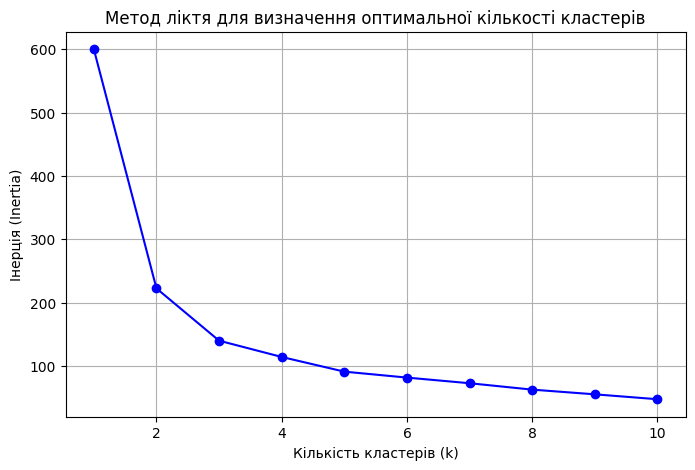

In [4]:
# Стандартизація даних
X = df_iris.drop(columns=['target']) if 'target' in df_iris.columns else df_iris
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Метод ліктя (Elbow Method) для визначення оптимальної кількості кластерів
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Побудова графіка методу ліктя
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Інерція (Inertia)')
plt.title('Метод ліктя для визначення оптимальної кількості кластерів')
plt.grid(True)

plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

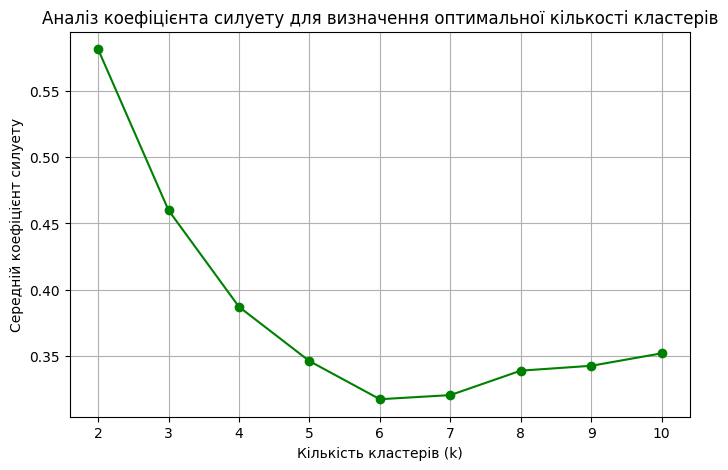

In [5]:
# Обчислення середнього коефіцієнта силуету для 2–10 кластерів
silhouette_scores = []
K_range_sil = range(2, 11)

for k in K_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(K_range_sil, silhouette_scores, marker='o', linestyle='-', color='g')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуету')
plt.title('Аналіз коефіцієнта силуету для визначення оптимальної кількості кластерів')
plt.grid(True)

plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

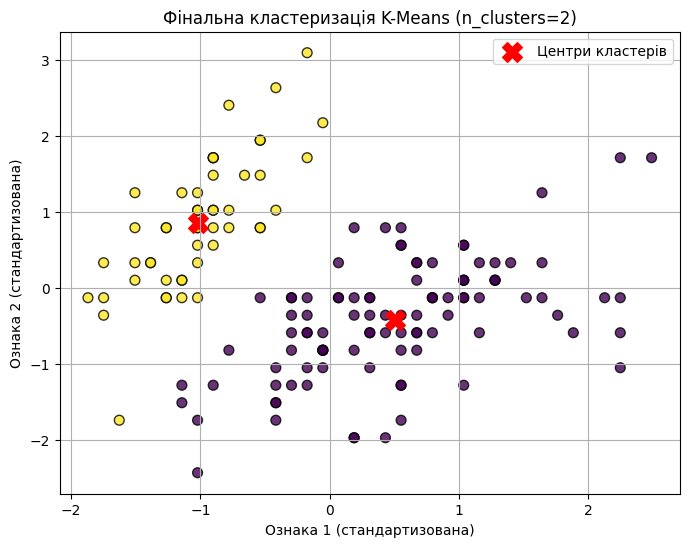

Координати центрів кластерів:
[[ 0.50728948 -0.42663134  0.65249366  0.62744675]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]]


In [6]:
# Навчання моделі K-Means для 2 кластерів
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
y_kmeans = kmeans_final.fit_predict(X_scaled) # fit_predict навчає і одночасно повертає мітки кластерів для кожн. т. даних

# Отримання координат центрів кластерів
centers = kmeans_final.cluster_centers_

# Візуалізація результатів кластеризації за першими двома ознаками
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_kmeans, cmap='viridis', s=50, alpha=0.8, edgecolor='k')

# Відображення центрів кластерів
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X', label='Центри кластерів')

plt.xlabel('Ознака 1 (стандартизована)')
plt.ylabel('Ознака 2 (стандартизована)')
plt.title('Фінальна кластеризація K-Means (n_clusters=2)')
plt.legend()
plt.grid(True)
plt.show()

print("Координати центрів кластерів:")
print(centers)

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Аналіз графіків показує, що метод ліктя має згин на значенні два або три, тоді як метод силуетів дає чіткий максимум саме для двох кластерів. Тому для фінальної кластеризації було обрано два кластери, це повністю узгоджується з отриманими графіками. Хоча у наборі даних є три види ірисів, два з них дуже схожі між собою та частково перетинаються, через це алгоритм об'єднує їх в один кластер, а найвідмінніший вид виділяє окремо.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [10]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [11]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [12]:
df.columns

Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [14]:
df.isnull().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [15]:
df.duplicated().sum()

np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [16]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [17]:
# Формування ознак (X) та цільової змінної (y)
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

# Поділ даних на навчальну та тестову вибірки (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Стандартизація ознак
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [18]:
# Налаштування сітки гіперпараметрів для Random Forest
param_grid_rf = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

# Ініціалізація моделі та GridSearchCV (5 згорток)
rf = RandomForestClassifier(random_state=42)
grid_search_rf = GridSearchCV(estimator=rf, param_grid=param_grid_rf, cv=5, scoring='accuracy')

# Запуск пошуку на навчальних даних
grid_search_rf.fit(X_train_scaled, y_train)

# Отримання найкращих результатів
best_rf = grid_search_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)
test_accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Найкращі параметри:", grid_search_rf.best_params_)
print("Середня CV-точність (Best Cross-Validation Score):", grid_search_rf.best_score_)
print("Тестова точність (Test Accuracy):", test_accuracy_rf)

Найкращі параметри: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}
Середня CV-точність (Best Cross-Validation Score): 0.9231460090495263
Тестова точність (Test Accuracy): 0.9102296450939458


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [20]:
# Налаштування сітки гіперпараметрів для Logistic Regression
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['saga'],
    'max_iter': [1000]
}

# Ініціалізація моделі та GridSearchCV (5 згорток)
lr = LogisticRegression(random_state=42)
grid_search_lr = GridSearchCV(estimator=lr, param_grid=param_grid_lr, cv=5, scoring='accuracy')

grid_search_lr.fit(X_train_scaled, y_train)

best_lr = grid_search_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)
test_accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Найкращі параметри:", grid_search_lr.best_params_)
print("Середня CV-точність (Best Cross-Validation Score):", grid_search_lr.best_score_)
print("Тестова точність (Test Accuracy):", test_accuracy_lr)

Найкращі параметри: {'C': 10, 'max_iter': 1000, 'solver': 'saga'}
Середня CV-точність (Best Cross-Validation Score): 0.7898404713408883
Тестова точність (Test Accuracy): 0.7432150313152401


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [21]:
# Налаштування сітки гіперпараметрів для Support Vector Machine (SVC)
param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 'auto']
}

# Ініціалізація моделі та GridSearchCV (5 згорток)
svm = SVC(random_state=42)
grid_search_svm = GridSearchCV(estimator=svm, param_grid=param_grid_svm, cv=5, scoring='accuracy')

grid_search_svm.fit(X_train_scaled, y_train)

best_svm = grid_search_svm.best_estimator_
y_pred_svm = best_svm.predict(X_test_scaled)
test_accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("Найкращі параметри:", grid_search_svm.best_params_)
print("Середня CV-точність (Best Cross-Validation Score):", grid_search_svm.best_score_)
print("Тестова точність (Test Accuracy):", test_accuracy_svm)

Найкращі параметри: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність (Best Cross-Validation Score): 0.8619947233879677
Тестова точність (Test Accuracy): 0.8288100208768268


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [22]:
# Збір результатів у словник для зручності
results = {
    "Random Forest": {
        "CV Score": grid_search_rf.best_score_,
        "Test Accuracy": test_accuracy_rf,
        "Model": best_rf
    },
    "Logistic Regression": {
        "CV Score": grid_search_lr.best_score_,
        "Test Accuracy": test_accuracy_lr,
        "Model": best_lr
    },
    "SVM": {
        "CV Score": grid_search_svm.best_score_,
        "Test Accuracy": test_accuracy_svm,
        "Model": best_svm
    }
}

# Виведення порівняльної таблиці точності
print(f"{'Модель':<22} | {'CV Точність':<15} | {'Тестова точність':<15}")
print("-" * 58)
for name, res in results.items():
    print(f"{name:<22} | {res['CV Score']:.4f}          | {res['Test Accuracy']:.4f}")

# Визначення найкращої моделі за CV-точчністю
best_model_name = max(results, key=lambda x: results[x]["CV Score"])
best_model = results[best_model_name]["Model"]

print(f"\nНайкраща модель за CV-точчністю: {best_model_name}")

# Виведення classification_report для найкращої моделі на тестових даних
y_pred_best = best_model.predict(X_test_scaled)
print("\nЗвіт класифікації (classification_report) для найкращої моделі:")
print(classification_report(y_test, y_pred_best))

Модель                 | CV Точність     | Тестова точність
----------------------------------------------------------
Random Forest          | 0.9231          | 0.9102
Logistic Regression    | 0.7898          | 0.7432
SVM                    | 0.8620          | 0.8288

Найкраща модель за CV-точчністю: Random Forest

Звіт класифікації (classification_report) для найкращої моделі:
              precision    recall  f1-score   support

         0.0       0.82      0.41      0.55        22
         1.0       0.80      0.88      0.83        49
         2.0       0.94      0.87      0.90        85
         3.0       0.89      0.90      0.89        86
         4.0       0.94      0.98      0.96       237

    accuracy                           0.91       479
   macro avg       0.88      0.81      0.83       479
weighted avg       0.91      0.91      0.91       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

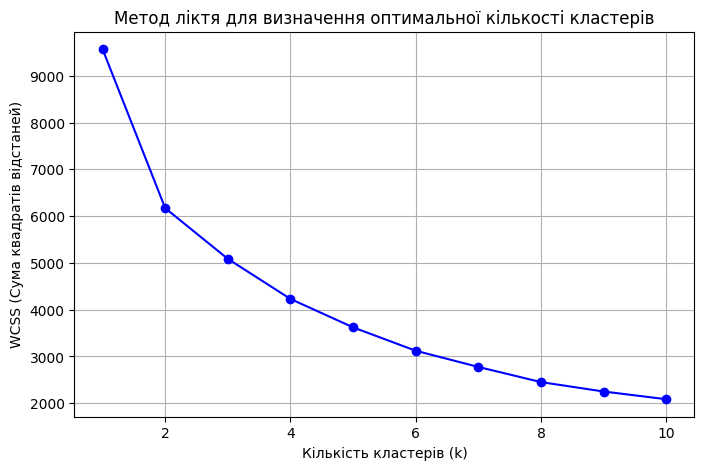

In [23]:
from sklearn.cluster import KMeans

# Вибір 4 числових ознак для кластеризації
features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_cluster = df[features]

# Стандартизація ознак
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

# Обчислення WCSS (суми квадратів відстаней) для 1–10 кластерів
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_cluster_scaled)
    wcss.append(kmeans.inertia_)

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-', color='b')
plt.title('Метод ліктя для визначення оптимальної кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Сума квадратів відстаней)')
plt.grid(True)

plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

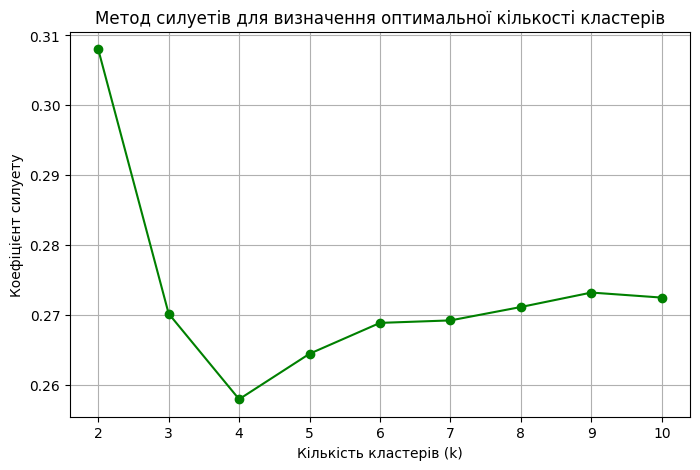

In [24]:
from sklearn.metrics import silhouette_score

# Обчислення коефіцієнта силуету для 2–10 кластерів
silhouette_scores = []
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_cluster_scaled)
    score = silhouette_score(X_cluster_scaled, cluster_labels)
    silhouette_scores.append(score)

# Побудова графіка коефіцієнта силуету
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='-', color='g')
plt.title('Метод силуетів для визначення оптимальної кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Коефіцієнт силуету')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [25]:
!pip install kneed yellowbrick -q

# Формування нового набору ознак
X_pca_data = df.drop(columns=['StudentID', 'GradeClass'])

# Стандартизація
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_data)

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [26]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [27]:
X_pca_input = df.drop(columns=['StudentID', 'GradeClass'])

# Застосування стандартизації та перетворення за допомогою PCA (напр., зменшення до 2 головних компонентів)
scaler_pca = StandardScaler()
X_scaled_pca = scaler_pca.fit_transform(X_pca_input)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled_pca)

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [30]:
# Навчання PCA
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled_pca)

# Отримання частки поясненої дисперсії для кожної компоненти
explained_variance_ratio = pca_full.explained_variance_ratio_

# Виведення результатів
for i, var in enumerate(explained_variance_ratio, 1):
    print(f"Компонента {i}: {var * 100:.2f}% поясненої дисперсії")

# Виведення накопичуваної дисперсії
print("\nНакопичувана пояснена дисперсія:", np.cumsum(explained_variance_ratio))

Компонента 1: 15.25% поясненої дисперсії
Компонента 2: 8.61% поясненої дисперсії
Компонента 3: 8.27% поясненої дисперсії
Компонента 4: 8.07% поясненої дисперсії
Компонента 5: 7.86% поясненої дисперсії
Компонента 6: 7.79% поясненої дисперсії
Компонента 7: 7.63% поясненої дисперсії
Компонента 8: 7.60% поясненої дисперсії
Компонента 9: 7.44% поясненої дисперсії
Компонента 10: 7.38% поясненої дисперсії
Компонента 11: 7.17% поясненої дисперсії
Компонента 12: 6.75% поясненої дисперсії
Компонента 13: 0.18% поясненої дисперсії

Накопичувана пояснена дисперсія: [0.15246911 0.23858271 0.32126156 0.40197981 0.48062807 0.55855881
 0.63486671 0.71087105 0.78527997 0.85907787 0.93075568 0.99821671
 1.        ]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Оптимальна кількість компонент за KneeLocator: 2


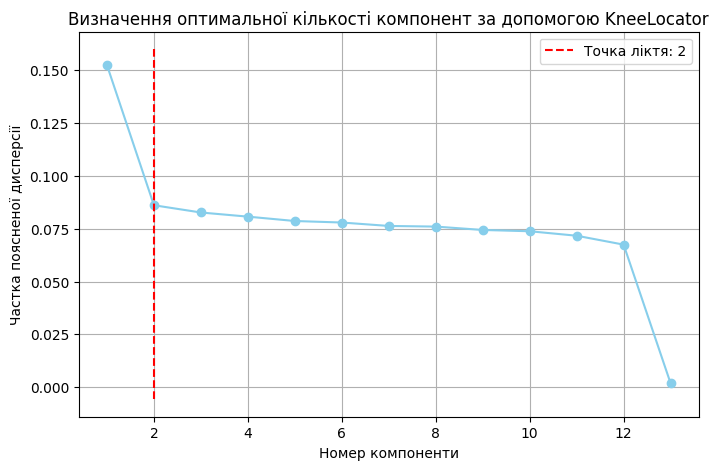

In [33]:
# Застосування KneeLocator для автоматичного знаходження точки згину (ліктя)
x_values = range(1, len(explained_variance_ratio) + 1)
kneedle = KneeLocator(
    x_values,
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)

optimal_components = kneedle.knee
print(f"Оптимальна кількість компонент за KneeLocator: {optimal_components}")

# Побудова графіка поясненої дисперсії з відміткою точки ліктя
plt.figure(figsize=(8, 5))
plt.plot(x_values, explained_variance_ratio, marker='o', linestyle='-', color='skyblue')
plt.vlines(optimal_components, plt.ylim()[0], plt.ylim()[1], linestyles='dashed', color='red', label=f'Точка ліктя: {optimal_components}')
plt.title('Визначення оптимальної кількості компонент за допомогою KneeLocator')
plt.xlabel('Номер компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.legend()
plt.grid(True)

plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

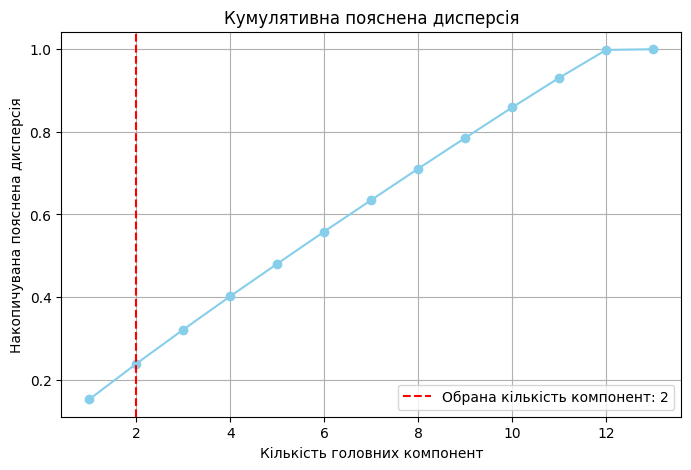

Фактична кумулятивна дисперсія для 2 компонент: 0.2386


In [36]:
# Побудова графіка кумулятивної поясненої дисперсії
cumulative_variance = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(8, 5))
plt.plot(x_values, cumulative_variance, marker='o', linestyle='-', color='skyblue')
plt.axvline(x=optimal_components, color='r', linestyle='--', label=f'Обрана кількість компонент: {optimal_components}')
plt.title('Кумулятивна пояснена дисперсія')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Накопичувана пояснена дисперсія')
plt.legend()
plt.grid(True)
plt.show()

# Виведення фактичної частки кумулятивної дисперсії для обраної кількості компонент
actual_variance = cumulative_variance[optimal_components - 1]
print(f"Фактична кумулятивна дисперсія для {optimal_components} компонент: {actual_variance:.4f}")

# Перетворення ознак через PCA
pca_final = PCA(n_components=optimal_components, random_state=42)
X_pca_final = pca_final.fit_transform(X_scaled_pca)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [37]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

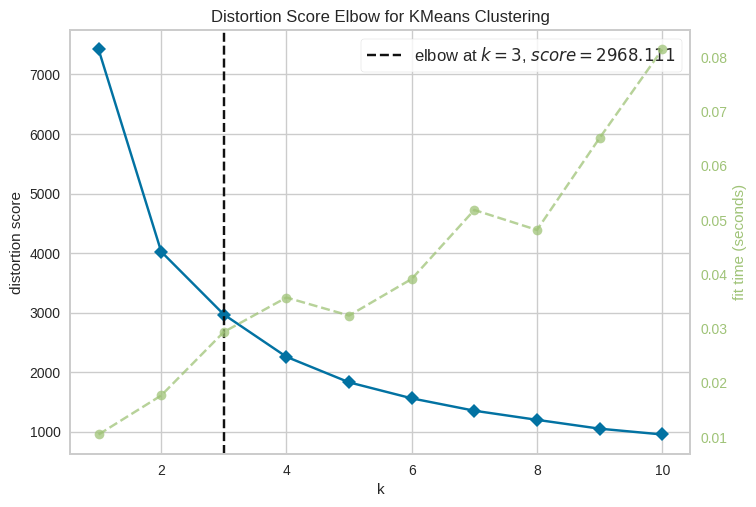

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [38]:
from sklearn.cluster import KMeans

# Ініціалізація моделі K-Means
model_kmeans = KMeans(random_state=42, n_init=10)

# Налаштування візуалізатора KElbowVisualizer для діапазону від 1 до 10 кластерів
visualizer = KElbowVisualizer(model_kmeans, k=(1, 11))

# Запуск візуалізатора на даних після PCA (X_pca_final)
visualizer.fit(X_pca_final)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

Порівняння методів визначення кількості кластерів показало, що класичний метод ліктя та метод силуетів відрізняються у результатах: силует вказує на два кластери, тоді як візуалізатор `KElbowVisualizer` на даних після PCA визначає оптимальну кількість у три кластери. Основна різниця між класифікацією за цільовою змінною `GradeClass` та кластеризацією полягає в тому, що класифікація належить до навчання з учителем і прогнозує відомі мітки, а кластеризація є навчанням без учителя, яке групує об'єкти за їхньою схожістю. Під час виконання аналізу методом головних компонент (PCA) було автоматично обрано дві головні компоненти, які пояснюють фактичну кумулятивну дисперсію на рівні 0.2386